# 04 · Games & player-play

Files: `games.csv`, `player_play.csv` (316k player-play rows for the rookie cohort).

**Questions:** How are snaps distributed across players/positions/games? What context and which role-specific metrics are populated? How do plays join to games and players?

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from utils import *
set_style()
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 160)

In [2]:
games = load_csv("games")
pp = load_csv("player_play")
players = load_csv("players")
print(games.shape, pp.shape)
pp.head(3)

(1002, 7) (314197, 64)


,game_id,play_id,team_abbr,nfl_id,lined_up_position,play_description,quarter,down,yards_to_go,possession_team,yardline_side,yardline_number,game_clock,pre_snap_home_score,pre_snap_visitor_score,play_direction,pre_snap_home_team_win_probability,pre_snap_visitor_team_win_probability,home_team_win_probability_added,visitor_team_win_probility_added,expected_points_added,expected_points,offense_formation,receiver_alignment,pass_result,pass_length,play_nullified_by_penalty,penalty_yards,pre_penalty_yards_gained,yards_gained,...,rec_yards,rush_yards,yards_after_catch,fumble,fumble_lost,route_ran,separation_at_pass_forward,cushion,expected_yards_after_catch,dropback_duration,extended_sack_allowed,pass_rushers_encountered,peak_pressure_probability_allowed,pressure_allowed,sack_allowed,time_to_pressure_allowed,quick_pressure,unblocked_pressure,blitzing,player_get_off,sack,tackle,assist,caused_forced_fumble,recovered_fumble,tackle_for_loss,time_to_pressure,time_to_qb_hurry,coverage_assignment,coverage_assignment_at_snap
0,2025111610,2279,BAL,57183,T,(8:42) (Shotgun) L.Jackson pass incomplete dee...,3,1,10,BAL,BAL,45,08:42,16,10,right,0.488722,0.511278,0.030960,-0.030960,-0.510282,2.716763,SHOTGUN,3x1,I,22.0,N,NaN,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.079,0.0,1.0,0.153333,False,0.0,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2026011701,1626,SF,58248,INTERIOR_LINE,(3:48) (Shotgun) K.Walker left end to SEA 28 f...,2,2,7,SEA,SEA,23,03:48,17,6,left,0.925716,0.074284,-0.002361,0.002361,-0.048963,0.357381,SHOTGUN,2x1,NaN,NaN,N,NaN,5,5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2025101900,2838,LAR,57140,EDGE,(7:01) C.Van Lanen reported in as eligible. T...,3,2,2,JAX,LAR,44,07:01,0,21,left,0.051319,0.948681,0.005685,-0.005685,0.927307,3.313706,SINGLEBACK,3x1,R,NaN,N,NaN,14,14,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,True,0.906,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NO_ASSIGNMENT,NO_ASSIGNMENT


## Games

season_type  POST  PRE  REG
season                     
2023           13   49  272
2024           13   49  272
2025           13   49  272


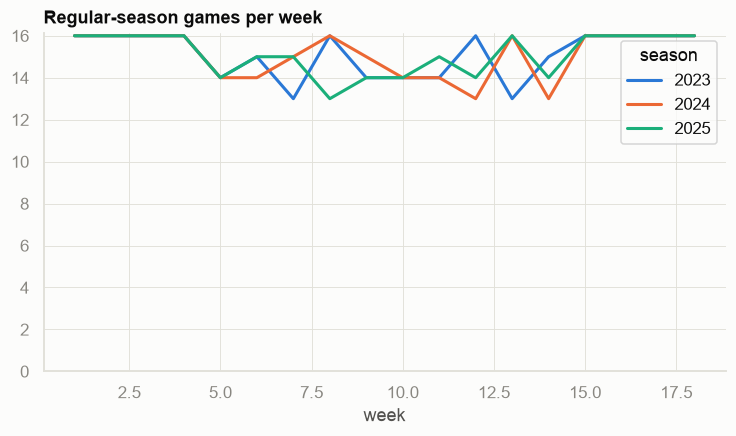

In [3]:
print(games.groupby(["season","season_type"]).size().unstack())
fig, ax = plt.subplots()
games[games.season_type == "REG"].groupby(["season","week"]).size().unstack(0).plot(ax=ax, color=PALETTE[:3]); ax.set_title("Regular-season games per week"); ax.set_ylim(0)
assert games.game_id.is_unique

## Join integrity

In [4]:
print("player_play games in games.csv:", pp.game_id.isin(games.game_id).mean())
print("player_play nfl_ids in players.csv:", pp.nfl_id.isin(players.nfl_id).mean(), "| players with >=1 play:", pp.nfl_id.nunique(), "/", len(players))
print("duplicate (game, play, player):", pp.duplicated(["game_id","play_id","nfl_id"]).sum())
pp = pp.merge(games[["game_id","season","season_type","week"]], on="game_id", how="left")

player_play games in games.csv: 1.0
player_play nfl_ids in players.csv: 1.0 | players with >=1 play: 497 / 510
duplicate (game, play, player): 0


In [5]:
missingness(pp).head(45)

,n_missing,pct_missing,dtype
rush_yards,314175,99.99,float64
fumble,314124,99.98,float64
fumble_lost,314124,99.98,float64
recovered_fumble,311983,99.30,object
quick_pressure,310434,98.80,object
time_to_pressure,310393,98.79,float64
time_to_qb_hurry,310318,98.77,float64
time_to_pressure_allowed,309227,98.42,float64
yards_after_catch,307937,98.01,float64
rec_yards,307937,98.01,float64


Nulls mostly reflect role-specific metrics (they only exist for linemen / rushers / targets). Below: non-null share of metric families by `lined_up_position`.

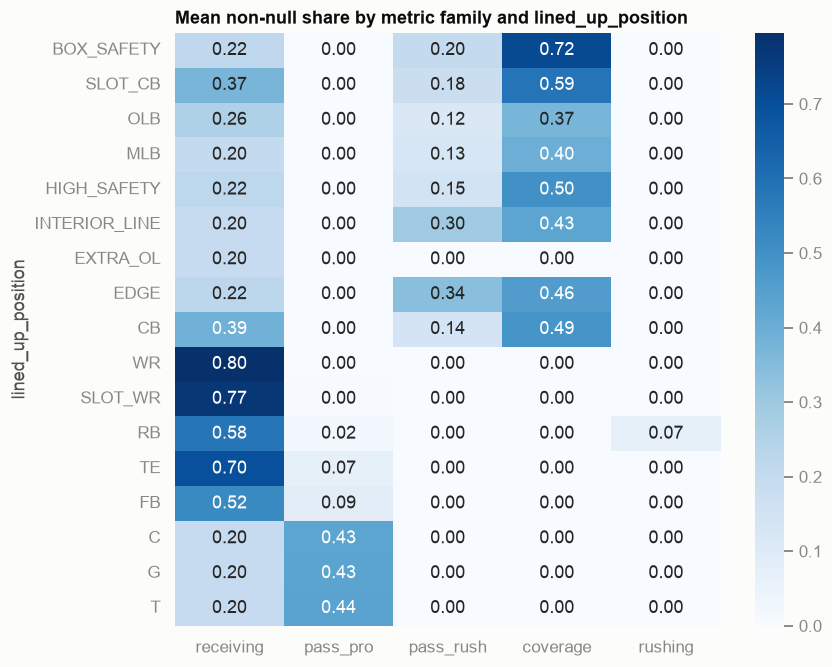

In [6]:
fam = {"receiving": ["target","rec_yards","route_ran","separation_at_pass_forward","cushion"],
       "pass_pro": ["pass_rushers_encountered","pressure_allowed","sack_allowed","time_to_pressure_allowed"],
       "pass_rush": ["player_get_off","time_to_pressure","quick_pressure","unblocked_pressure"],
       "coverage": ["coverage_assignment","coverage_assignment_at_snap"], "rushing": ["rush_yards"]}
cov = pd.DataFrame({k: pp.groupby("lined_up_position")[v].apply(lambda g: g.notna().mean().mean()) for k, v in fam.items()})
cov["n"] = pp.lined_up_position.value_counts()
fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(cov.drop(columns="n").sort_values("pass_pro"), annot=True, fmt=".2f", cmap="Blues", ax=ax); ax.set_title("Mean non-null share by metric family and lined_up_position")
savefig(fig, "04_role_coverage")

## Snaps

          rows  players  games
season                        
2023     50755      156    333
2024    108524      318    334
2025    154918      448    334


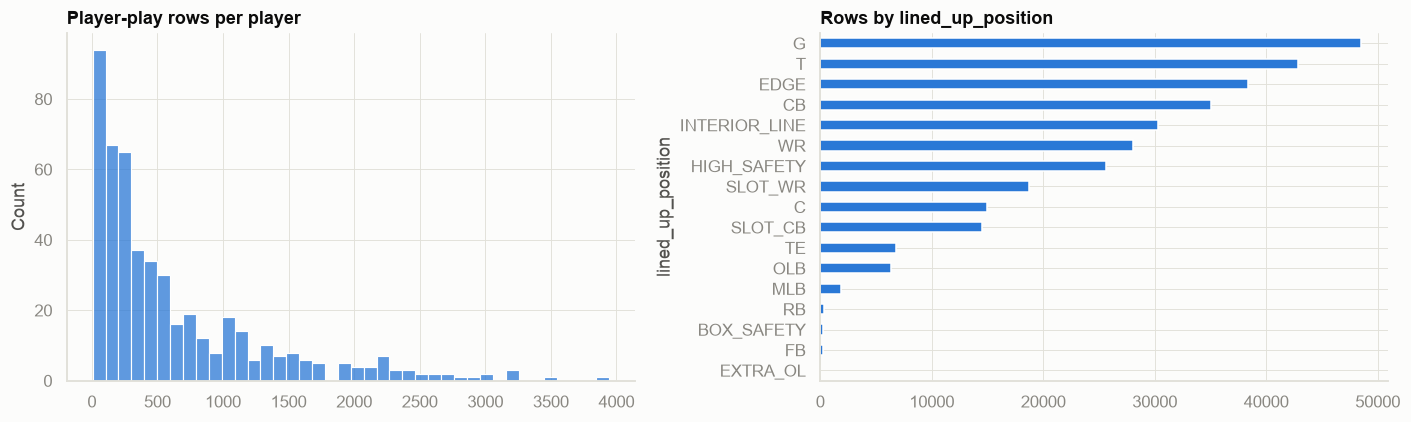

In [7]:
snaps = pp.groupby("nfl_id").size()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(snaps, bins=40, color=PALETTE[0], ax=axes[0]); axes[0].set_title("Player-play rows per player")
pp.lined_up_position.value_counts().plot.barh(color=PALETTE[0], ax=axes[1]).invert_yaxis(); axes[1].set_title("Rows by lined_up_position")
plt.tight_layout(); savefig(fig, "04_snaps")
print(pp.groupby("season").agg(rows=("play_id","size"), players=("nfl_id","nunique"), games=("game_id","nunique")))

## Situation context

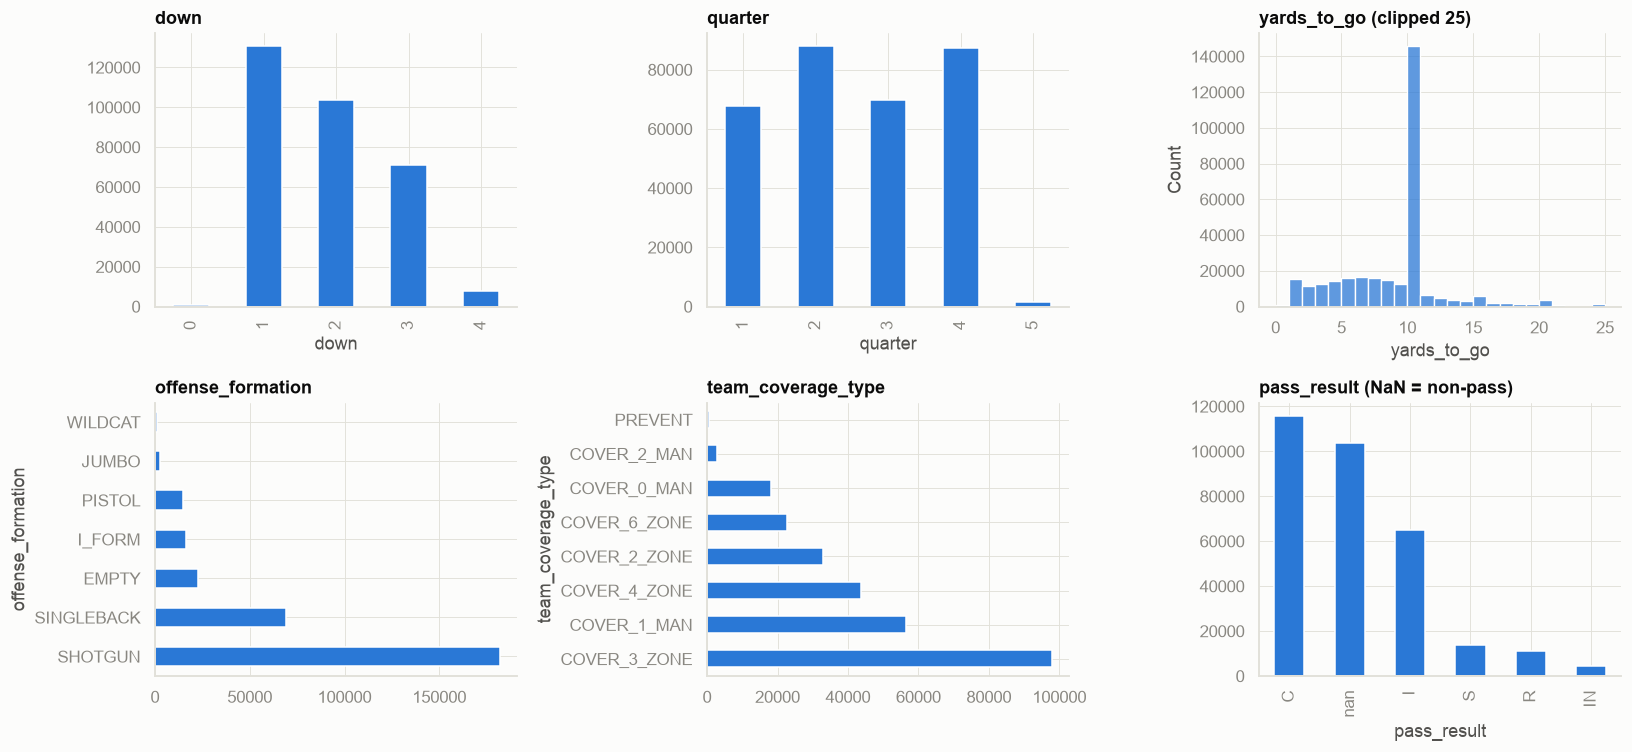

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
pp.down.value_counts().sort_index().plot.bar(color=PALETTE[0], ax=axes[0,0]).set_title("down")
pp.quarter.value_counts().sort_index().plot.bar(color=PALETTE[0], ax=axes[0,1]).set_title("quarter")
sns.histplot(pp.yards_to_go.clip(upper=25), bins=25, color=PALETTE[0], ax=axes[0,2]).set_title("yards_to_go (clipped 25)")
pp.offense_formation.value_counts().plot.barh(color=PALETTE[0], ax=axes[1,0]).set_title("offense_formation")
pp.team_coverage_type.value_counts().plot.barh(color=PALETTE[0], ax=axes[1,1]).set_title("team_coverage_type")
pp.pass_result.value_counts(dropna=False).plot.bar(color=PALETTE[0], ax=axes[1,2]).set_title("pass_result (NaN = non-pass)")
plt.tight_layout(); savefig(fig, "04_context")

## EPA / win probability

unique plays: 114954
                                    count      mean       std        min         1%       50%        99%        max
expected_points_added            114954.0 -0.053298  1.419458 -12.896382  -4.842362 -0.209782   3.717492   8.968813
expected_points                  114954.0  2.345953  1.614648  -2.899994  -0.917797  2.163751   6.180325   6.656688
home_team_win_probability_added  114952.0 -0.000039  0.041744  -0.992924  -0.119038  0.000007   0.121051   0.993080
yards_gained                     114954.0  5.047558  8.833384 -99.000000 -10.000000  3.000000  38.000000  98.000000


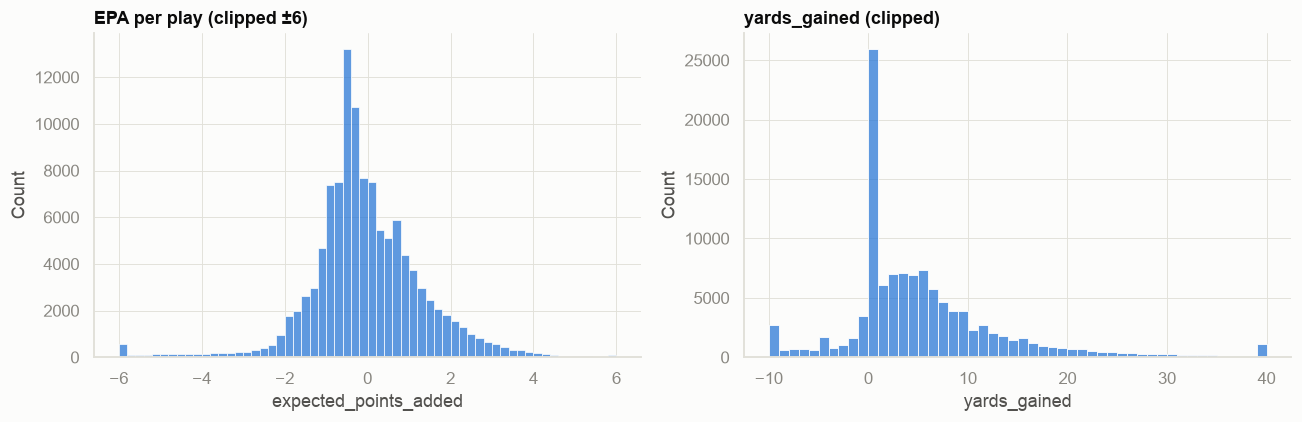

In [9]:
u = pp.drop_duplicates(["game_id","play_id"])
print("unique plays:", len(u)); print(u[["expected_points_added","expected_points","home_team_win_probability_added","yards_gained"]].describe(percentiles=[.01,.5,.99]).T)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(u.expected_points_added.clip(-6, 6), bins=60, color=PALETTE[0], ax=axes[0]); axes[0].set_title("EPA per play (clipped ±6)")
sns.histplot(u.yards_gained.clip(-10, 40), bins=50, color=PALETTE[0], ax=axes[1]); axes[1].set_title("yards_gained (clipped)")
plt.tight_layout()

In [10]:
print(pp.play_nullified_by_penalty.value_counts(normalize=True).round(4))
print("home+visitor WPA sums to ~0:", np.allclose(pp.home_team_win_probability_added + pp.visitor_team_win_probility_added, 0, atol=1e-6))

play_nullified_by_penalty
N    0.9602
Y    0.0398
Name: proportion, dtype: float64
home+visitor WPA sums to ~0: False


## Role-specific distributions

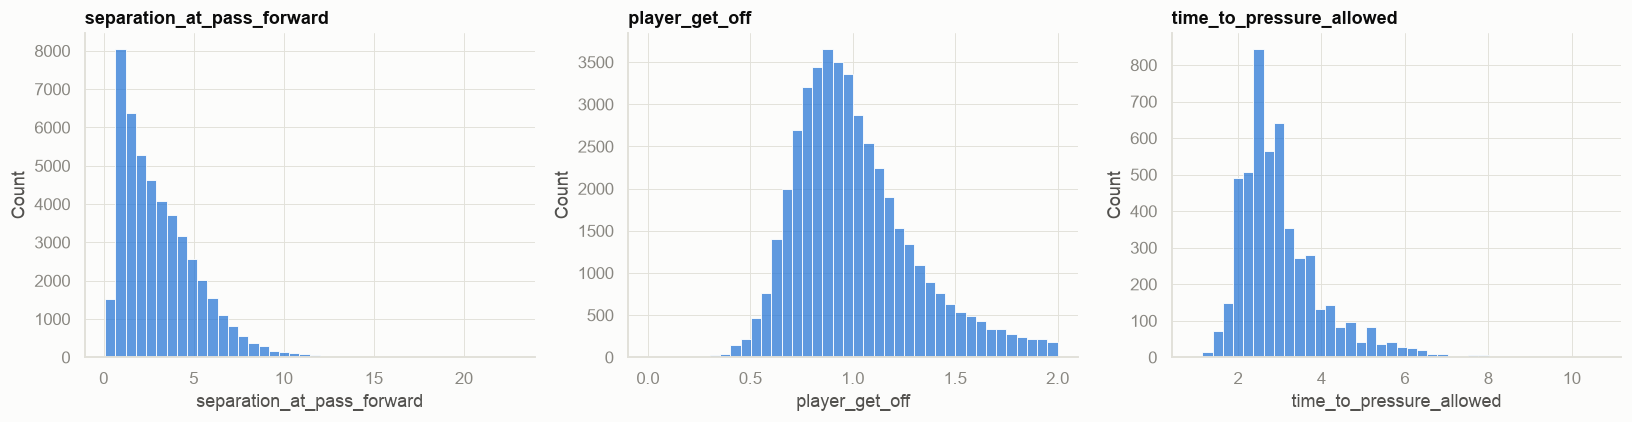

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(pp.separation_at_pass_forward.dropna(), bins=40, color=PALETTE[0], ax=axes[0]).set_title("separation_at_pass_forward")
sns.histplot(pp.player_get_off.dropna(), bins=40, color=PALETTE[0], ax=axes[1]).set_title("player_get_off")
sns.histplot(pp.time_to_pressure_allowed.dropna(), bins=40, color=PALETTE[0], ax=axes[2]).set_title("time_to_pressure_allowed")
plt.tight_layout(); savefig(fig, "04_role_metrics")

In [12]:
pp["is_target"] = pp.target.fillna(False).astype(bool)
rec = pp[pp.route_ran.notna()]
print("target rate by route:"); print(rec.groupby("route_ran").is_target.agg(["mean","size"]).sort_values("size", ascending=False).round(3))

target rate by route:
            mean  size
route_ran             
GO         0.125  9715
HITCH      0.197  8816
CROSS      0.208  6756
IN         0.128  5582
OUT        0.262  5179
POST       0.123  4865
CORNER     0.106  4232
SLANT      0.236  3413
FLAT       0.201  3287
SCREEN     0.652  1321
WHEEL      0.217    83
ANGLE      0.305    59


## Findings / follow-ups
- Fill in after reviewing outputs.